In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Learn how to get started at https://www.tidymodels.o

In [2]:
gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss <- gss |> drop_na(realinc, educ)

gss |> glimpse()

Rows: 67,731
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


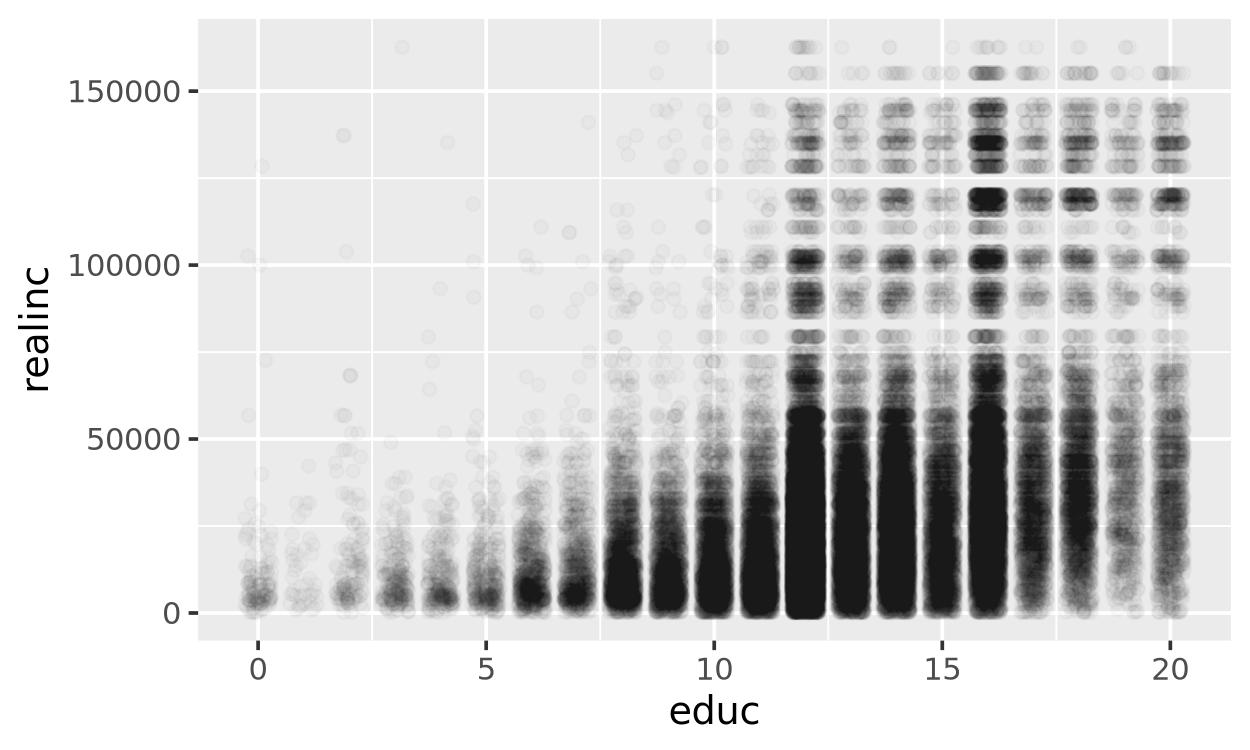

In [3]:
ggplot(gss, aes(x = educ, y = realinc)) +
    geom_jitter(alpha = 0.02, width = 0.3)

In [4]:
income_by_educ <- gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc))

income_by_educ |> head()

  educ realinc 
1 0    11642.46
2 1    12030.38
3 2    18330.32
4 3    11435.07
5 4    11648.34
6 5    12475.96

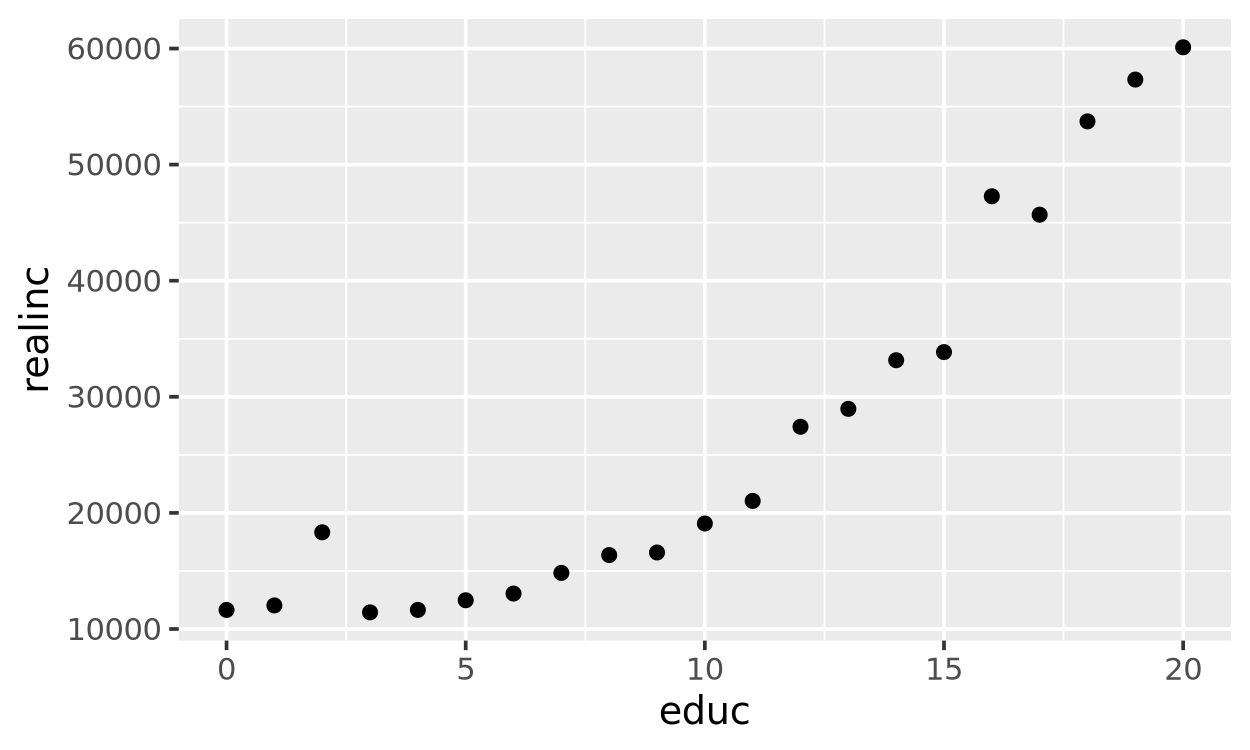

In [5]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) + geom_point()

In [6]:
set.seed(512)

models <- tibble(
    a1 = runif(250, -40000, 40000),
    a2 = runif(250, -5000, 10000)
)

models |> head()

  a1         a2        
1  -9173.383   598.0216
2 -29290.667 -2076.9564
3  -3459.260  9205.7161
4  34594.730  3199.3232
5  11499.913  2164.0763
6 -24210.921  6572.8802

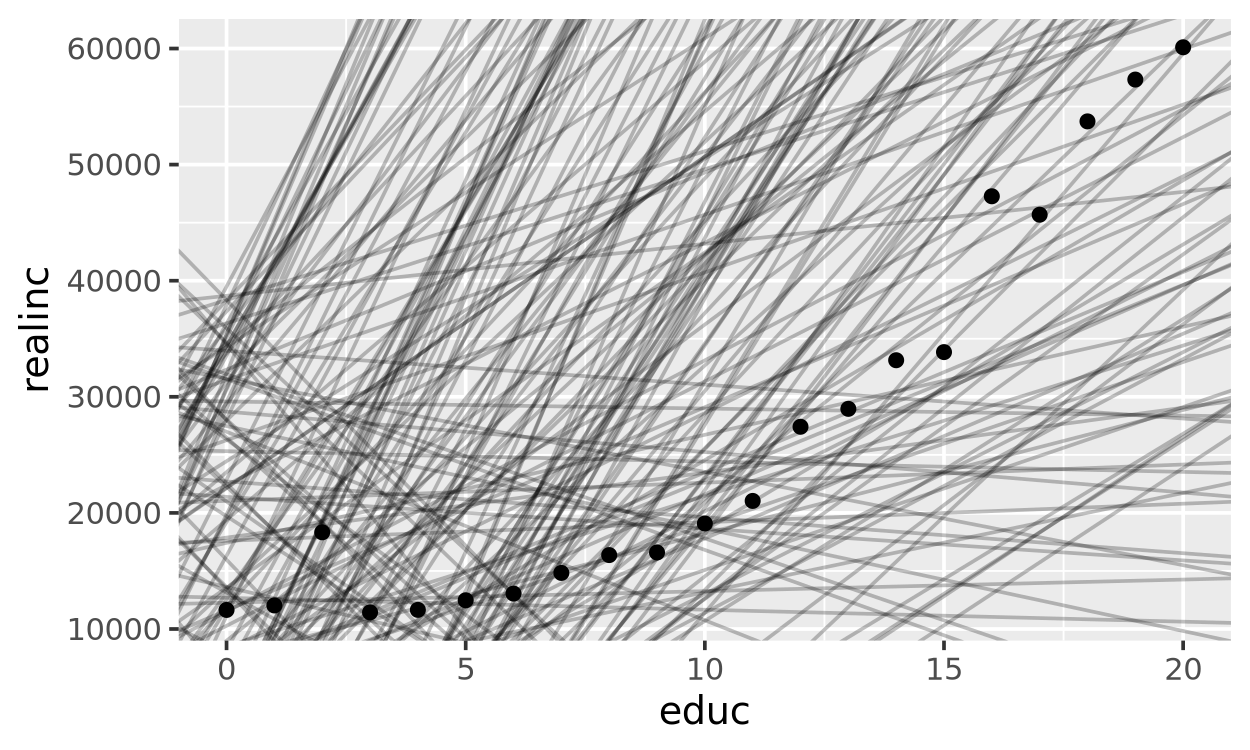

In [7]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(aes(intercept = a1, slope = a2), data = models, alpha = 0.25) +
    geom_point()

In [8]:
model1 <- function(a, data) {
    a[1] + data$educ * a[2]
}

model1(c(-5000, 3000), income_by_educ)

 [1] -5000 -2000  1000  4000  7000 10000 13000 16000 19000 22000 25000 28000
[13] 31000 34000 37000 40000 43000 46000 49000 52000 55000

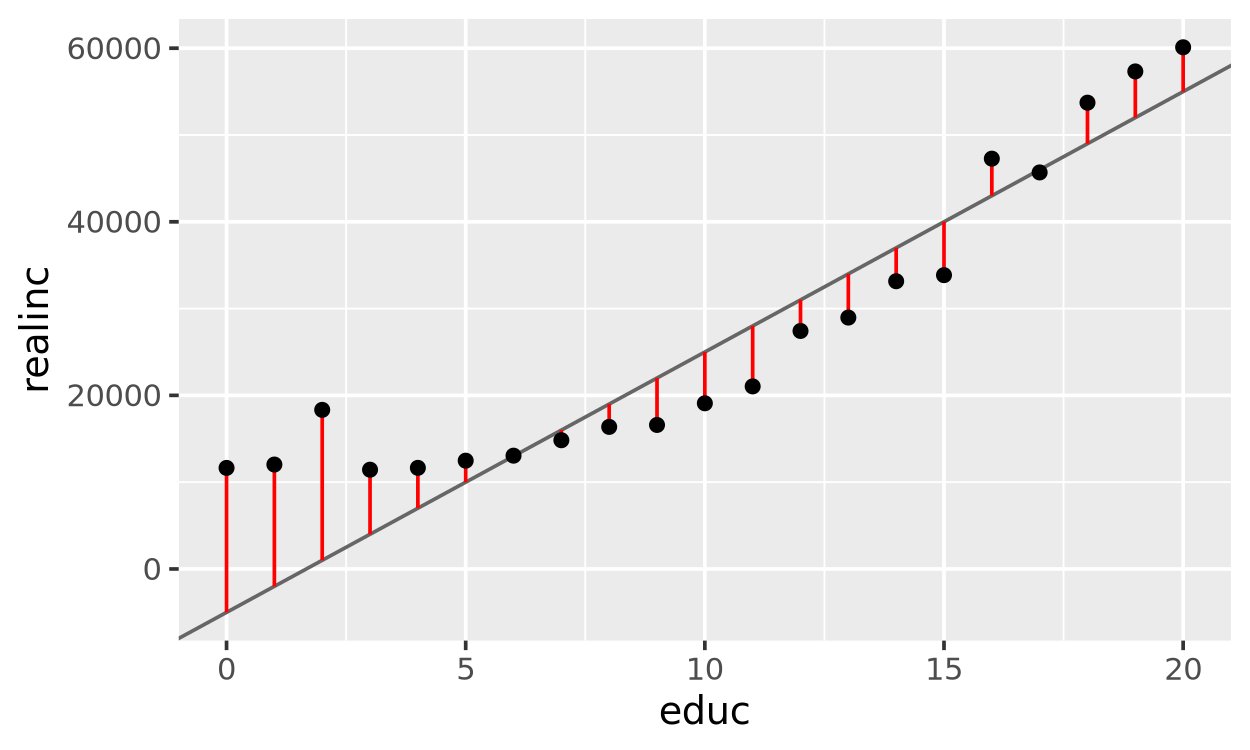

In [9]:
income_by_educ |>
    mutate(pred = model1(c(-5000, 3000), income_by_educ)) |>
ggplot(aes(x = educ)) +
    geom_abline(intercept = -5000, slope = 3000, color = 'grey40') +
    geom_segment(aes(y = realinc, yend = pred), color = 'red') +
    geom_point(aes(y = realinc))

In [10]:
measure_distance <- function(mod, data) {
    diff <- data$realinc - model1(mod, data)
    sqrt(mean(diff ^ 2))
}

measure_distance(c(-5000, 3000), gss)

[1] 28421.63

In [12]:
gss_dist <- function(a1, a2) {
    measure_distance(c(a1, a2), gss)
}

models <- models |>
    mutate(dist = map2_dbl(a1, a2, gss_dist))

models |> arrange(dist) |> head()

  a1          a2       dist    
1 -11784.8668 3301.585 28328.10
2 -18773.1984 3967.549 28339.56
3    442.4071 2410.560 28541.08
4 -29549.6118 4841.924 28623.94
5   8217.2376 2038.907 28819.50
6 -32283.5692 5173.781 28923.82

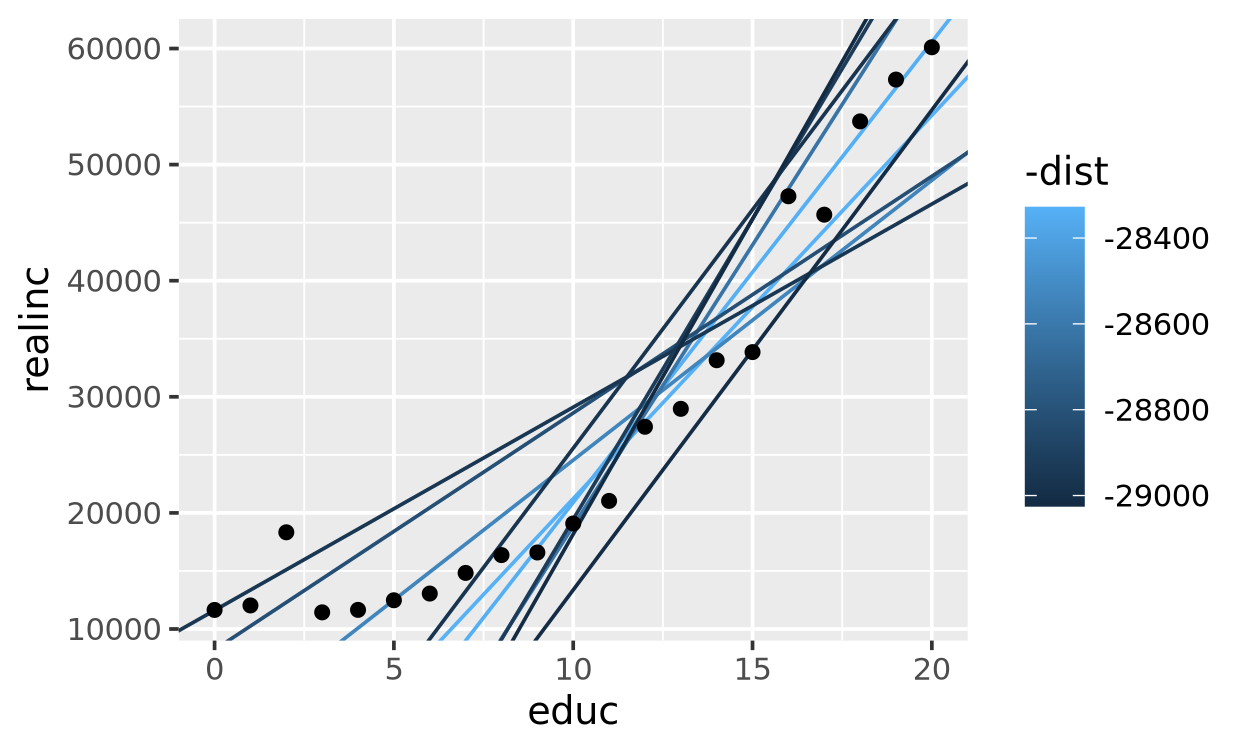

In [13]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(
        aes(intercept = a1, slope = a2, color = -dist),
        data = models |> slice_min(dist, n = 10)
    ) +
    geom_point()

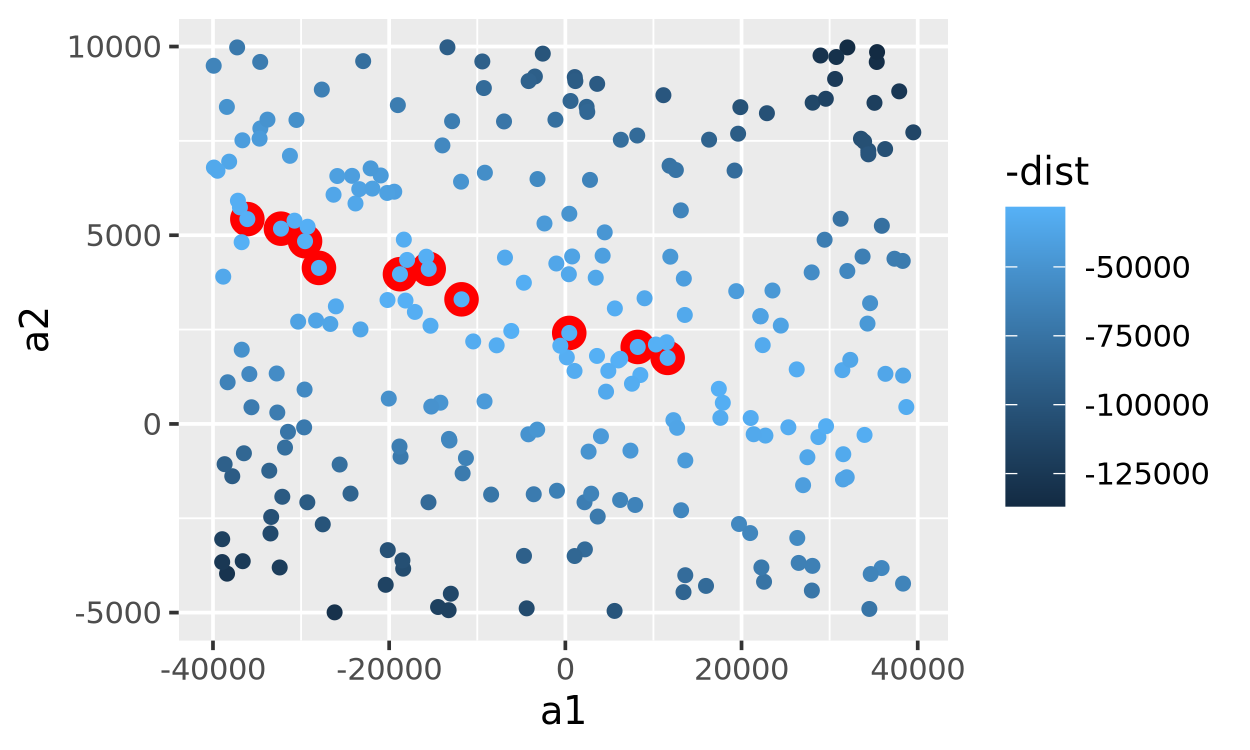

In [14]:
ggplot(models, aes(x = a1, y = a2)) +
    geom_point(data = models |> slice_min(dist, n = 10), size = 4, color = 'red') +
    geom_point(aes(color = -dist))

In [15]:
grid <- expand_grid(
    a1 = seq(-25000, -5000, length = 25),
    a2 = seq(2500, 4500, length = 25)
) |>
    mutate(dist = map2_dbl(a1, a2, gss_dist))

grid |> arrange(dist) |> head()

  a1        a2       dist    
1 -13333.33 3500.000 28301.22
2 -15833.33 3666.667 28301.81
3 -14166.67 3583.333 28302.72
4 -15000.00 3583.333 28303.15
5 -12500.00 3416.667 28304.59
6 -16666.67 3750.000 28305.35

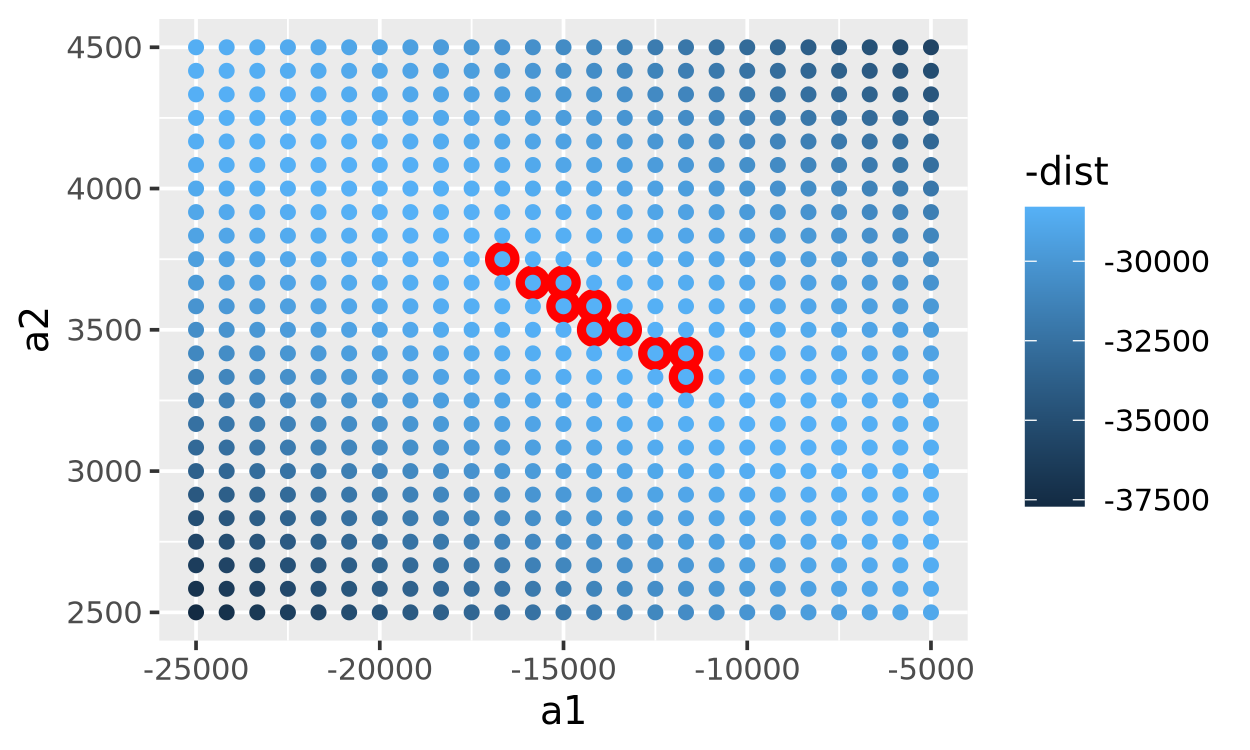

In [16]:
ggplot(grid, aes(x = a1, y = a2)) +
    geom_point(data = grid |> slice_min(dist, n = 10), size = 4, color = 'red') +
    geom_point(aes(color = -dist))

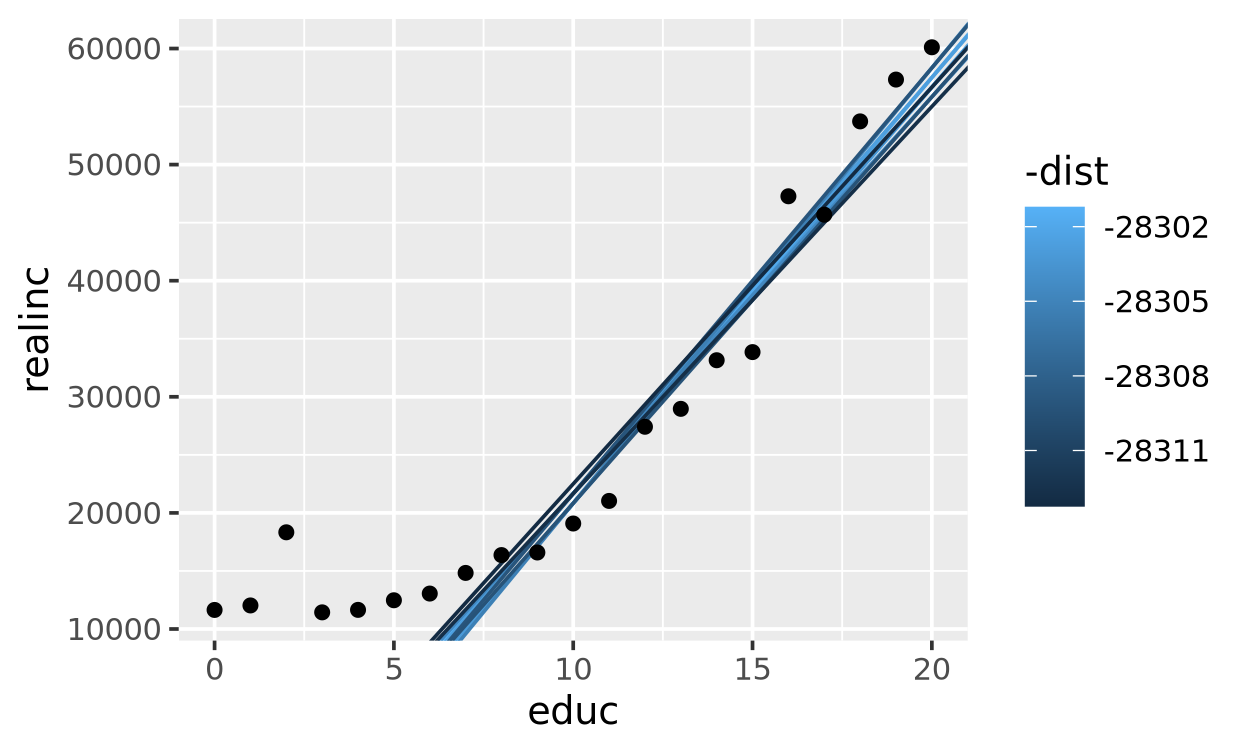

In [17]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(
        aes(intercept = a1, slope = a2, color = -dist),
        data = grid |> slice_min(dist, n = 10)
    ) +
    geom_point()

In [18]:
start <- models |> slice_min(dist, n = 1)

start

  a1        a2       dist   
1 -11784.87 3301.585 28328.1

In [19]:
best <- optim(c(start$a1, start$a2), measure_distance, data = gss)

best$par

[1] -14493.137   3577.444

In [20]:
best$value

[1] 28299.86

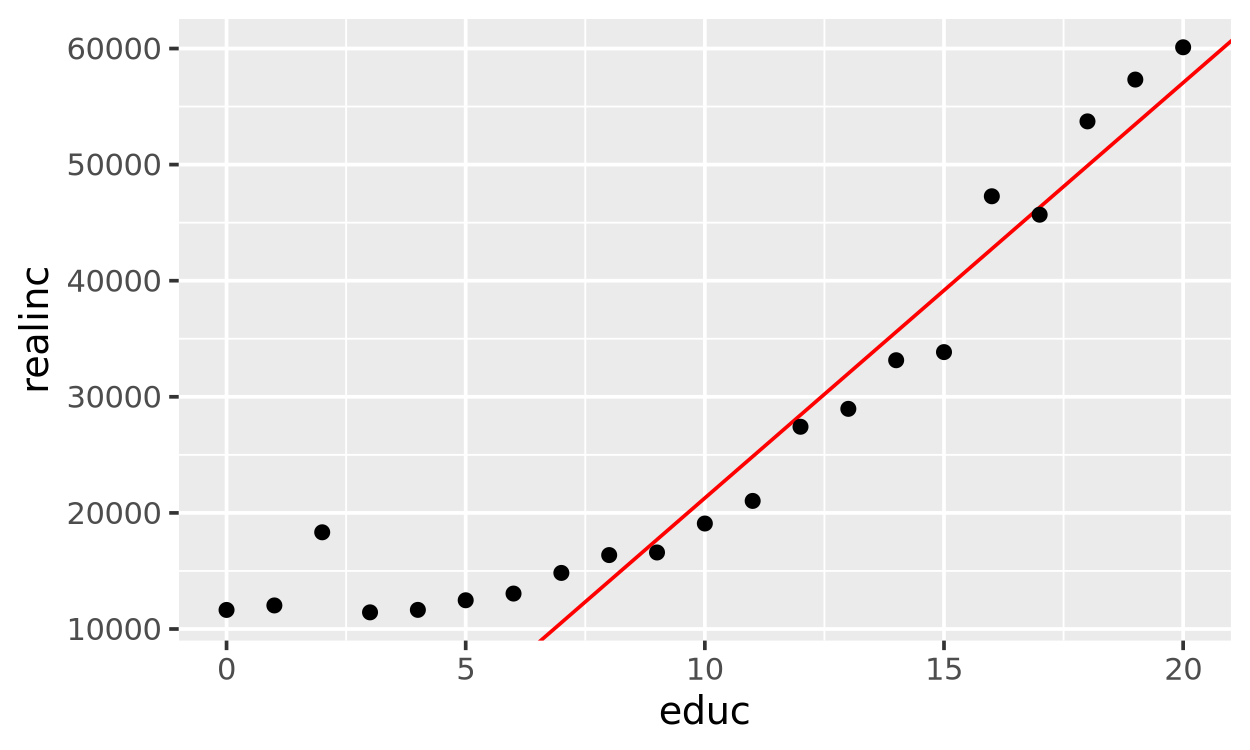

In [21]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(intercept = best$par[1], slope = best$par[2], color = 'red') +
    geom_point()

In [22]:
optim(c(0, 0), measure_distance, data = gss)$par

[1]  464.5525 2500.3898

In [23]:
path <- tibble()

measure_distance_log <- function(mod, data) {
    dist <- measure_distance(mod, data)
    path <<- bind_rows(path, tibble(a1 = mod[1], a2 = mod[2], dist = dist))
    dist
}

In [24]:
path <- tibble()

optim(c(start$a1, start$a2), measure_distance_log, data = gss)$par

path_good <- path |> mutate(step = row_number(), start = 'best random model')

path_good |> head()

  a1        a2       dist     step start            
1 -11784.87 3301.585 28328.10 1    best random model
2 -10606.38 3301.585 28314.28 2    best random model
3 -11784.87 4480.071 31961.34 3    best random model
4 -10606.38 2123.098 32468.87 4    best random model
5 -11490.25 3890.828 29199.34 5    best random model
6 -10901.00 2712.341 29477.98 6    best random model

In [25]:
surface <- expand_grid(
    a1 = seq(-25000, 5000, length = 60),
    a2 = seq(0, 5000, length = 60)
) |>
    mutate(dist = map2_dbl(a1, a2, gss_dist))

In [26]:
levels <- min(surface$dist) + 100 * 2^(0:10)

levels

 [1]  28399.99  28499.99  28699.99  29099.99  29899.99  31499.99  34699.99
 [8]  41099.99  53899.99  79499.99 130699.99

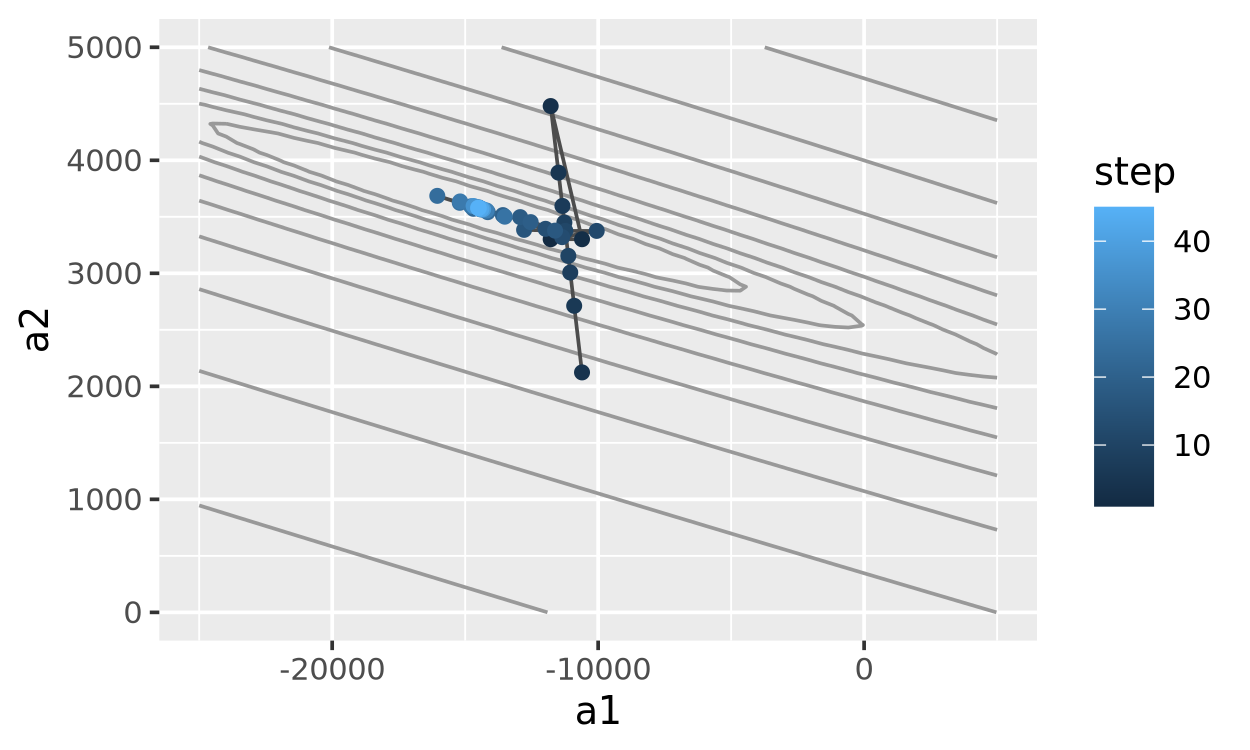

In [27]:
ggplot(path_good, aes(x = a1, y = a2)) +
    geom_contour(aes(z = dist), data = surface, breaks = levels, color = 'grey60') +
    geom_path(color = 'grey30') +
    geom_point(aes(color = step))

In [28]:
fit1 <- linear_reg() |> fit(realinc ~ educ, data = gss)

fit1

parsnip model object


Call:
stats::lm(formula = realinc ~ educ, data = data)

Coefficients:
(Intercept)         educ  
     -14472         3576  


In [29]:
best$par

[1] -14493.137   3577.444

In [30]:
grid_educ <- tibble(educ = 0:20)

preds <- fit1 |> predict(new_data = grid_educ) |> bind_cols(grid_educ)

preds |> head()

  .pred       educ
1 -14472.0096 0   
2 -10896.0428 1   
3  -7320.0761 2   
4  -3744.1093 3   
5   -168.1425 4   
6   3407.8243 5   

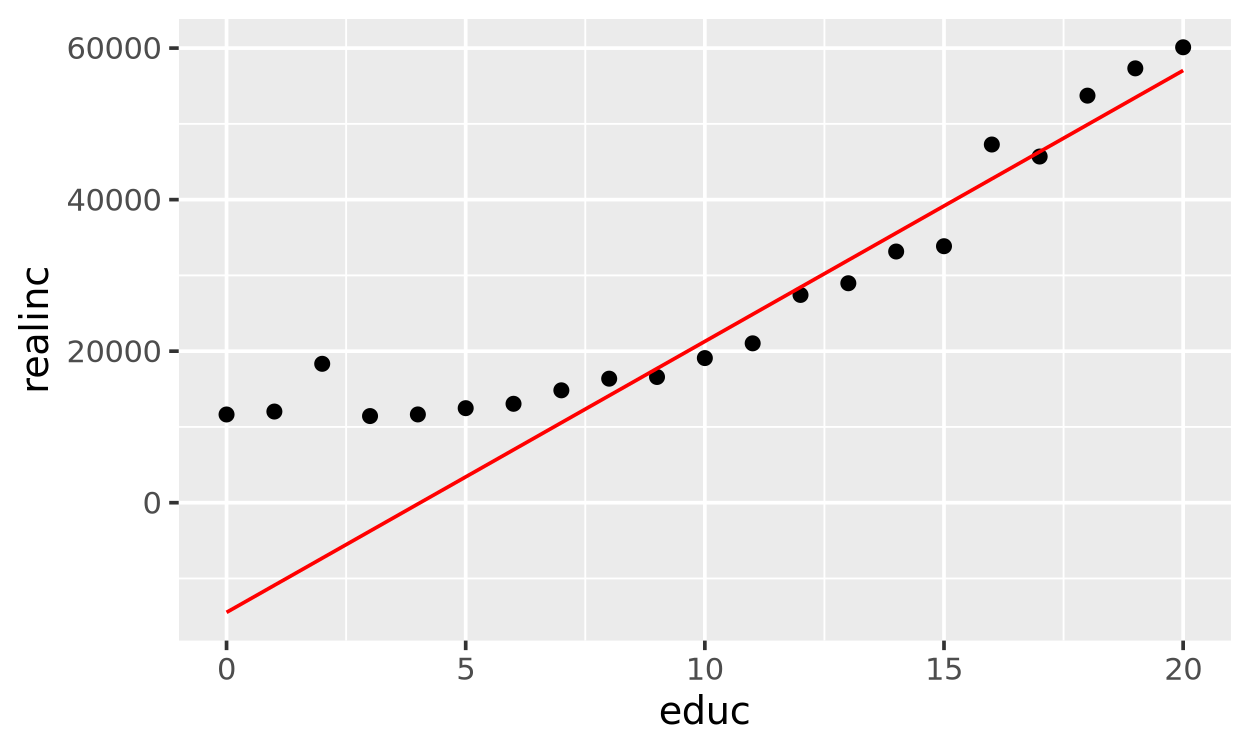

In [31]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_point() +
    geom_line(data = preds, aes(y = .pred), color = 'red')

In [32]:
measure_distance_mae <- function(mod, data) {
    diff <- data$realinc - model1(mod, data)
    mean(abs(diff))
}

best_mae <- optim(best$par, measure_distance_mae, data = gss)

best_mae$par

[1] -8370.077  2563.523

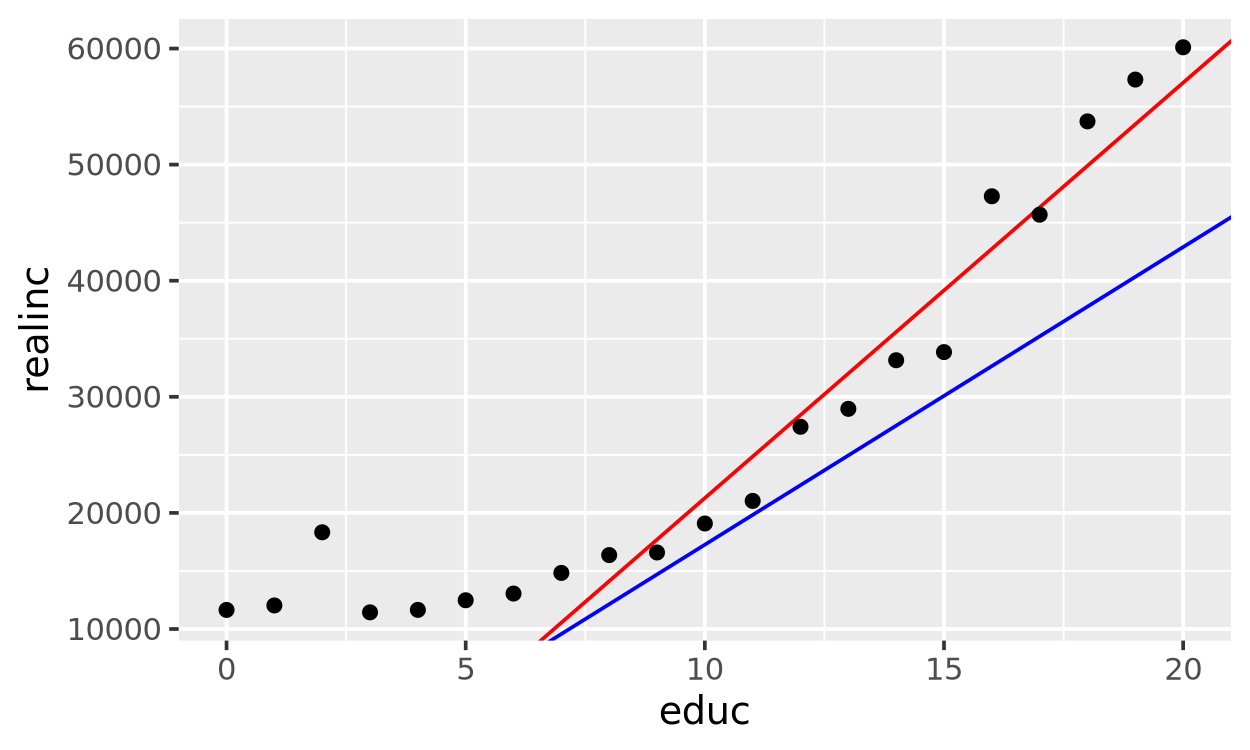

In [33]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(intercept = best$par[1], slope = best$par[2], color = 'red') +
    geom_abline(intercept = best_mae$par[1], slope = best_mae$par[2], color = 'blue') +
    geom_point()